# Projeto de Predição de Churn e Agrupamento de Clientes — Model Fitness

## Apresentação e Introdução do Projeto

### A rotatividade de clientes (churn) é um dos desafios operacionais e financeiros mais críticos no segmento de academias e serviços por assinatura. Reter um cliente ativo possui um custo de aquisição (CAC) substancialmente menor do que atrair um novo membro. No contexto da Model Fitness, a perda de clientes muitas vezes ocorre de maneira silenciosa: o usuário reduz a frequência semanal, encerra seus treinos em grupo e, por fim, deixa de comparecer no mês seguinte sem solicitar cancelamento formal prévio.

### O objetivo deste projeto é construir uma estratégia de retenção orientada a dados (data-driven) por meio de Machine Learning e segmentação comportamental. O fluxo de trabalho engloba:

- Identificar os fatores determinantes e comportamentais associados à evasão de clientes.
- Desenvolver e comparar modelos de classificação supervisionada (Regressão Logística vs. Random Forest) para estimar a probabilidade de churn individual no mês seguinte.
- Realizar clusterização não supervisionada (Dendrograma Hierárquico e K-Means) para mapear os perfis típicos de frequentadores (buyer personas).
- Formular um plano tático de inteligência de negócios com recomendações práticas para mitigar a rotatividade e maximizar o Lifetime Value (LTV).

## Passo 1: Carregamento e Visão Geral dos Dados
- O primeiro passo consiste na importação das bibliotecas analíticas, carregamento do arquivo , padronização das nomenclaturas de colunas para snake_case e inspeção das propriedades estruturais da base de dados.**gym_churn_us.csv**

In [2]:
# Importação das bibliotecas essenciais para manipulação, visualização e modelagem
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [3]:
# Configuração estética dos gráficos
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Carregamento do conjunto de dados
df = pd.read_csv('/datasets/gym_churn_us.csv')

# Padronização dos nomes das colunas para minúsculas
df.columns = df.columns.str.lower()

# Exibição das dimensões e primeiras linhas da base
print(f'Dimensões do conjunto de dados: {df.shape[0]} linhas e {df.shape[1]} colunas.')
print('\nPrimeiras 5 linhas:')
display(df.head())

# Verificação de tipos de dados e contagem explícita de valores ausentes
print('\nInformações gerais da estrutura do DataFrame:')
print(df.info())

print('\nContagem explícita de valores ausentes por coluna:')
print(df.isna().sum())

# Verificação explícita de linhas duplicadas
num_duplicatas = df.duplicated().sum()
print(f'\nTotal de linhas duplicadas encontradas: {num_duplicatas}')

Dimensões do conjunto de dados: 4000 linhas e 14 colunas.

Primeiras 5 linhas:


,gender,near_location,partner,promo_friends,phone,contract_period,group_visits,age,avg_additional_charges_total,month_to_end_contract,lifetime,avg_class_frequency_total,avg_class_frequency_current_month,churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0



Informações gerais da estrutura do DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   near_location                      4000 non-null   int64  
 2   partner                            4000 non-null   int64  
 3   promo_friends                      4000 non-null   int64  
 4   phone                              4000 non-null   int64  
 5   contract_period                    4000 non-null   int64  
 6   group_visits                       4000 non-null   int64  
 7   age                                4000 non-null   int64  
 8   avg_additional_charges_total       4000 non-null   float64
 9   month_to_end_contract              4000 non-null   float64
 10  lifetime                           4000 non-null   int64  
 11  avg_class

### Conclusão do Passo 1:
- O conjunto de dados é composto por 4.000 registros e 14 variáveis (13 preditoras e a variável-alvo binária `churn`).
- A checagem explícita confirmou que **não há valores ausentes** (`df.isna().sum()` igual a 0 em todas as colunas) e **não há linhas duplicadas** (`df.duplicated().sum() == 0`), eliminando a necessidade de imputação manual ou remoção de dados.
- Todas as variáveis categóricas binárias (`gender`, `near_location`, `partner`, `promo_friends`, `phone` e `group_visits`) e a variável-alvo `churn` já se encontram codificadas numericamente no formato 0 e 1.

## Passo 2: Análise Exploratória dos Dados (AED)
- Nesta etapa, analisamos as distribuições estatísticas gerais, as diferenças médias de perfil entre clientes retidos e evadidos, o comportamento bimodal ou enviesado das variáveis contínuas e o grau de multicolinearidade entre os atributos.

In [5]:
# 1. Estatísticas descritivas gerais (média, desvio padrão, mínimos, quartis e máximos)
print('--- Estatísticas Descritivas Gerais ---')
display(df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])

--- Estatísticas Descritivas Gerais ---


,count,mean,std,min,25%,50%,75%,max
gender,4000.0,0.510250,0.499957,0.000000,0.000000,1.000000,1.000000,1.000000
near_location,4000.0,0.845250,0.361711,0.000000,1.000000,1.000000,1.000000,1.000000
partner,4000.0,0.486750,0.499887,0.000000,0.000000,0.000000,1.000000,1.000000
promo_friends,4000.0,0.308500,0.461932,0.000000,0.000000,0.000000,1.000000,1.000000
phone,4000.0,0.903500,0.295313,0.000000,1.000000,1.000000,1.000000,1.000000
contract_period,4000.0,4.681250,4.549706,1.000000,1.000000,1.000000,6.000000,12.000000
group_visits,4000.0,0.412250,0.492301,0.000000,0.000000,0.000000,1.000000,1.000000
age,4000.0,29.184250,3.258367,18.000000,27.000000,29.000000,31.000000,41.000000
avg_additional_charges_total,4000.0,146.943728,96.355602,0.148205,68.868830,136.220159,210.949625,552.590740
month_to_end_contract,4000.0,4.322750,4.191297,1.000000,1.000000,1.000000,6.000000,12.000000


In [6]:
# 2. Médias dos atributos agrupadas pelo status de rotatividade (Churn: 0 = Ficou, 1 = Saiu)
print('\n--- Médias dos Atributos Agrupadas por Churn ---')
churn_grouped = df.groupby('churn').mean().T
churn_grouped.columns = ['Ficou (Churn = 0)', 'Saiu (Churn = 1)']
churn_grouped['Diferença Absoluta'] = churn_grouped['Saiu (Churn = 1)'] - churn_grouped['Ficou (Churn = 0)']
display(churn_grouped)


--- Médias dos Atributos Agrupadas por Churn ---


,Ficou (Churn = 0),Saiu (Churn = 1),Diferença Absoluta
gender,0.510037,0.510839,0.000801
near_location,0.873086,0.768143,-0.104943
partner,0.534195,0.355325,-0.178870
promo_friends,0.353522,0.183789,-0.169733
phone,0.903709,0.902922,-0.000787
contract_period,5.747193,1.728558,-4.018635
group_visits,0.464103,0.268615,-0.195489
age,29.976523,26.989632,-2.986890
avg_additional_charges_total,158.445715,115.082899,-43.362816
month_to_end_contract,5.283089,1.662582,-3.620507


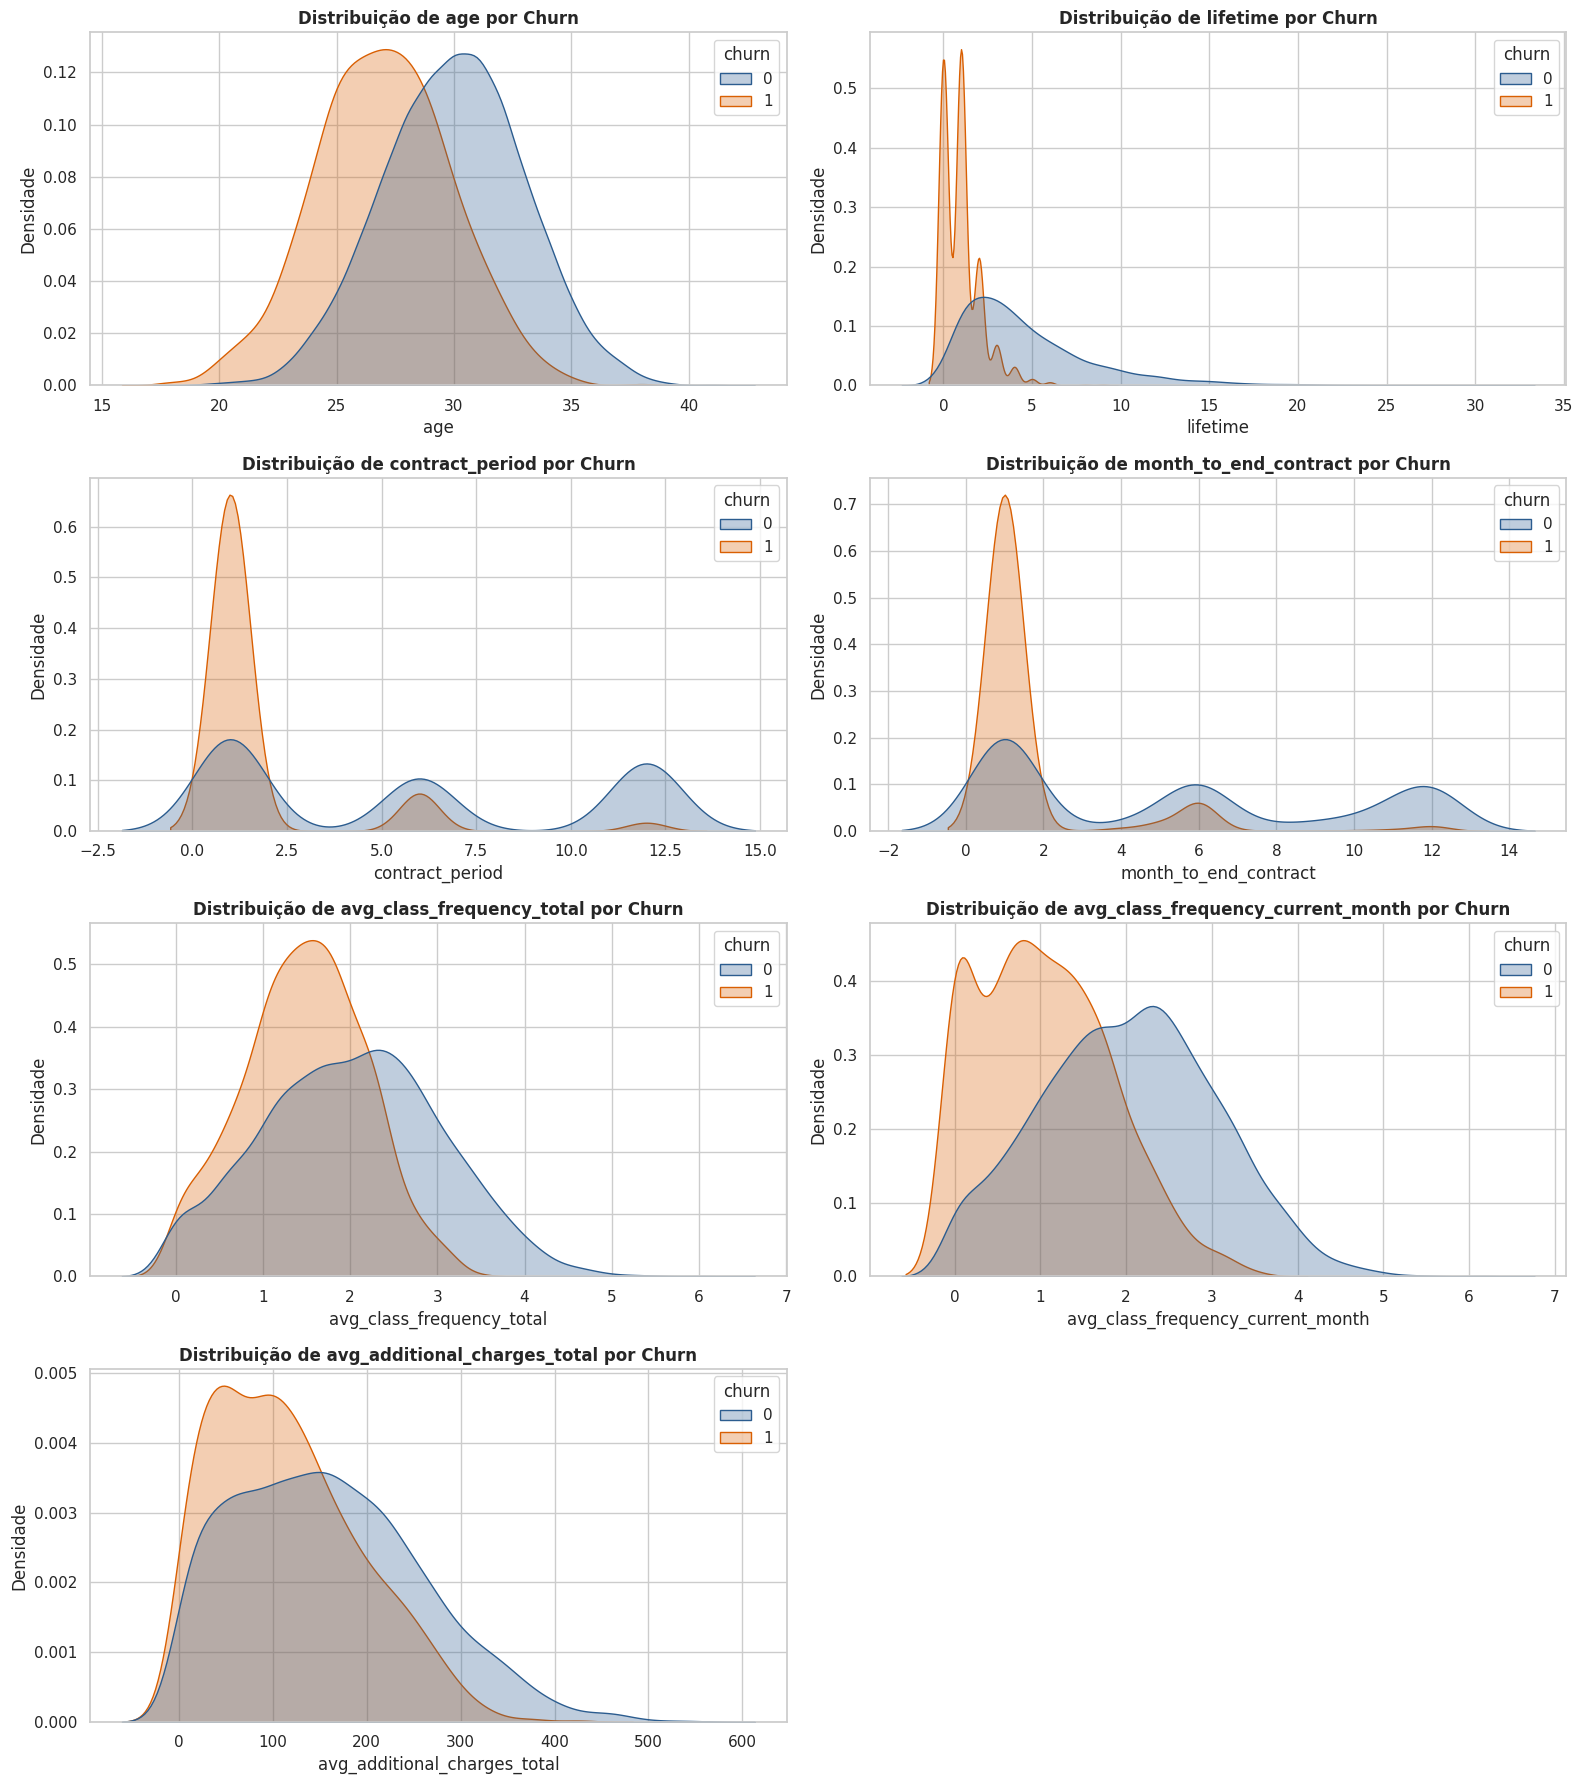

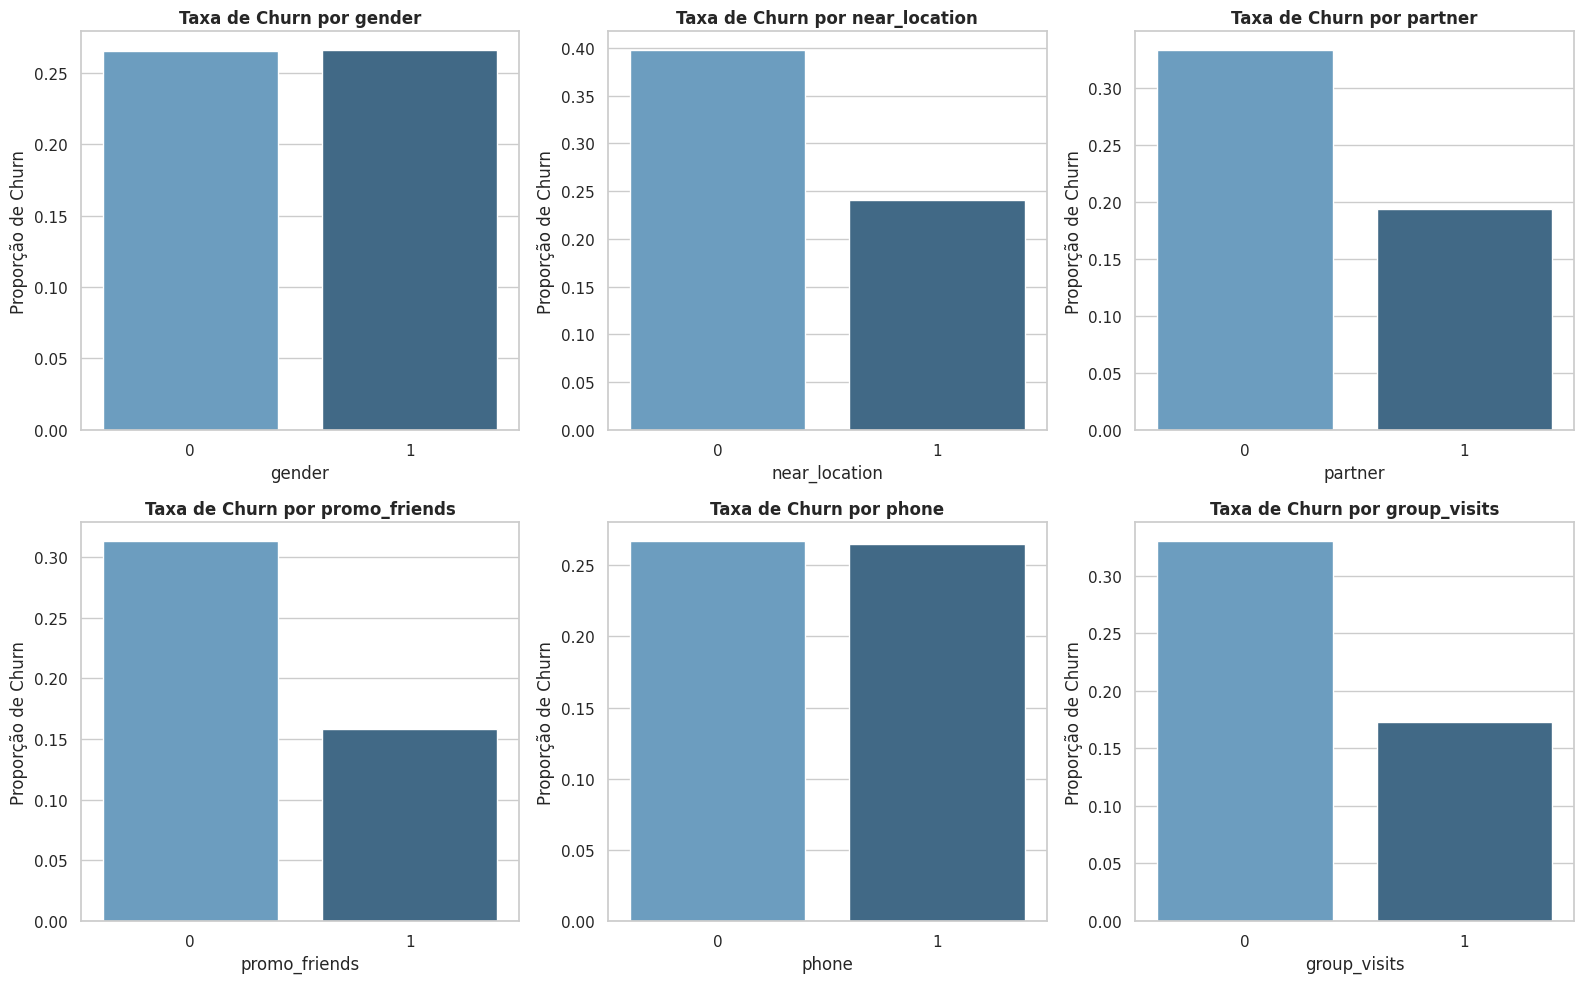

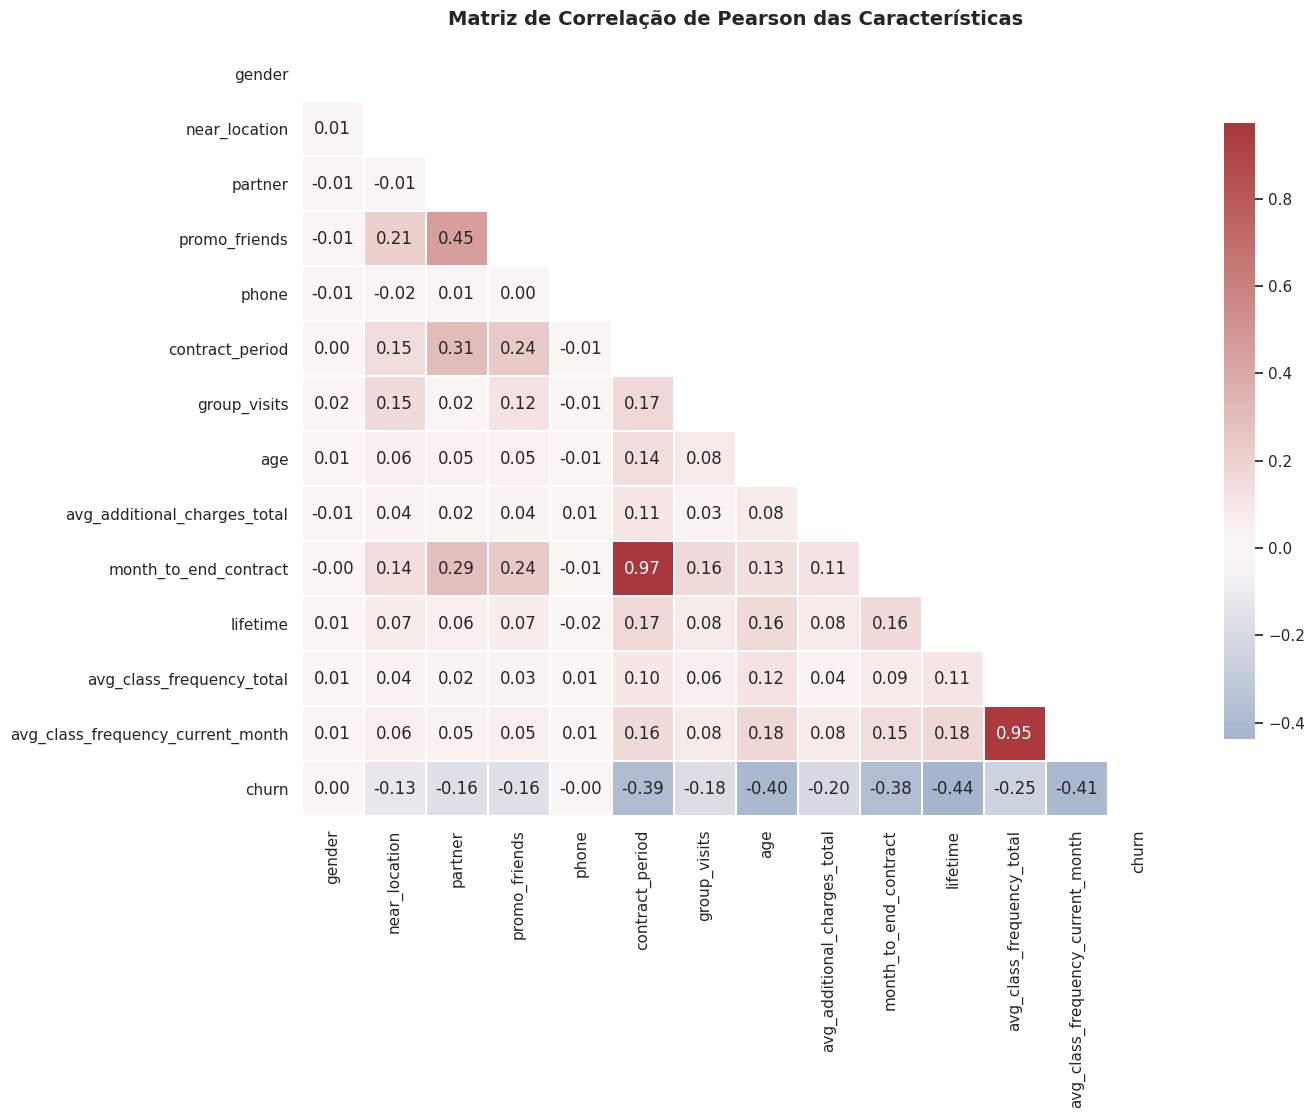


Correlação de cada atributo com o Churn (ordenada):


lifetime                            -0.438220
avg_class_frequency_current_month   -0.412348
age                                 -0.404735
contract_period                     -0.389984
month_to_end_contract               -0.381393
avg_class_frequency_total           -0.249715
avg_additional_charges_total        -0.198697
group_visits                        -0.175325
promo_friends                       -0.162233
partner                             -0.157986
near_location                       -0.128098
phone                               -0.001177
gender                               0.000708
churn                                1.000000
Name: churn, dtype: float64

In [7]:
# 3. Distribuição e Histogramas para quem saiu vs quem ficou
continuous_cols = [
    'age',
    'lifetime',
    'contract_period',
    'month_to_end_contract',
    'avg_class_frequency_total',
    'avg_class_frequency_current_month',
    'avg_additional_charges_total',
]
binary_cols = ['gender', 'near_location', 'partner', 'promo_friends', 'phone', 'group_visits']

# Plotagem de variáveis contínuas
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 18))
axes = axes.flatten()

for idx, col in enumerate(continuous_cols):
    sns.kdeplot(
        data=df,
        x=col,
        hue='churn',
        common_norm=False,
        palette=['#2b5c8f', '#d95f02'],
        fill=True,
        alpha=0.3,
        ax=axes[idx],
    )
    axes[idx].set_title(f'Distribuição de {col} por Churn', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Densidade')

# Ocultar o último subplot excedente
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

# Plotagem de variáveis binárias/categóricas
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
axes = axes.flatten()

for idx, col in enumerate(binary_cols):
    sns.barplot(
        data=df,
        x=col,
        y='churn',
        palette='Blues_d',
        ax=axes[idx],
        ci=None,
    )
    axes[idx].set_title(f'Taxa de Churn por {col}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Proporção de Churn')

plt.tight_layout()
plt.show()

# 4. Matriz de Correlação e Mapa de Calor (Heatmap)
plt.figure(figsize=(14, 10))
correlation_matrix = df.corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='vlag',
    center=0,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
)
plt.title('Matriz de Correlação de Pearson das Características', fontsize=14, fontweight='bold', pad=15)
plt.show()

# Exibição de correlações diretas com a variável Churn
print('\nCorrelação de cada atributo com o Churn (ordenada):')
display(correlation_matrix['churn'].sort_values())

### Conclusão do Passo 2:
- **Taxa basal de evasão:** O churn global da base é de 26,5% (1.061 cancelamentos em 4.000 clientes).
- **Fatores comportamentais críticos:**
    - **Queda de frequência semanal:** Clientes retidos frequentam em média 2,03 vezes/semana no mês corrente. Os clientes que evadiram caíram sua frequência média para 1,04 vez/semana (uma redução de ~48%).
    - **Tempo de casa (`lifetime`):** Membros que cancelaram possuem média de permanência de apenas 0,99 mês (menos de 30 dias), contra 4,71 meses dos clientes fiéis.
    - **Duração do contrato (`contract_period`):** A média de contrato de quem permaneceu é de 5,75 meses, contra 1,73 mês entre os que abandonaram, demonstrando alta vulnerabilidade dos planos mensais.
    - **Gastos em serviços adicionais (`avg_additional_charges_total`):** Clientes retidos gastam em média $158,45 no ecossistema da academia, contra $115,08 dos evadidos.
- **Multicolinearidade detectada:**
    - Observa-se correlação quase perfeita (\(r = 0,97\)) entre as variáveis `contract_period` e `month_to_end_contract`.
    - Observa-se forte correlação (\(r = 0,95\)) entre `avg_class_frequency_total` e `avg_class_frequency_current_month`.
    - As características `gender` (\(r = 0,0007\)) e `phone` (\(r = -0,0012\)) demonstraram correlação linear praticamente nula com a evasão de clientes.

## Passo 3: Construção do Modelo Preditivo de Churn
- Para predizer se um cliente cancelará no mês subsequente, formulamos um problema de classificação binária supervisionada. Comparamos dois estimadores canônicos: Regressão Logística e Floresta Aleatória (Random Forest), avaliando suas performances no conjunto de teste via validação estratificada por amostragem aleatória fixa ().

In [9]:
# 1. Separação de variáveis explicativas (X) e alvo (y)
X = df.drop('churn', axis=1)
y = df['churn']

In [10]:
# 2. Divisão treino e teste (80% treino / 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0, stratify=y
)

In [11]:
# 3. Padronização das variáveis preditoras (StandardScaler ajustado apenas no treino)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
# 4. Treinamento da Regressão Logística
lr_model = LogisticRegression(random_state=0, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
lr_predictions = lr_model.predict(X_test_scaled)
lr_probabilities = lr_model.predict_proba(X_test_scaled)[:, 1]


In [13]:
# 5. Treinamento da Floresta Aleatória (Random Forest)
rf_model = RandomForestClassifier(n_estimators=100, random_state=0)
rf_model.fit(X_train_scaled, y_train)
rf_predictions = rf_model.predict(X_test_scaled)
rf_probabilities = rf_model.predict_proba(X_test_scaled)[:, 1]

In [14]:

# 6. Função de cálculo e consolidação das métricas
def evaluate_model(y_true, y_pred, y_prob, model_name):
    return {
        'Modelo': model_name,
        'Acurácia (Accuracy)': accuracy_score(y_true, y_pred),
        'Precisão (Precision)': precision_score(y_true, y_pred),
        'Sensibilidade (Recall)': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
    }

metrics_list = [
    evaluate_model(y_test, lr_predictions, lr_probabilities, 'Regressão Logística'),
    evaluate_model(y_test, rf_predictions, rf_probabilities, 'Random Forest Classifier'),
]

metrics_df = pd.DataFrame(metrics_list)
print('--- Comparação de Desempenho dos Modelos ---')
display(metrics_df.round(4))

--- Comparação de Desempenho dos Modelos ---


,Modelo,Acurácia (Accuracy),Precisão (Precision),Sensibilidade (Recall),F1-Score,ROC-AUC
0,Regressão Logística,0.9350,0.896,0.8538,0.8744,0.9780
1,Random Forest Classifier,0.9225,0.875,0.8255,0.8495,0.9703


### Conclusão do Passo 3:
- **Comparação das Métricas no Conjunto de Validação:**
    - **Regressão Logística:** Acurácia de 93,50%, Precisão de 89,60%, Sensibilidade (Recall) de 85,38%, F1-Score de 87,44% e ROC-AUC de 0,9780.
    - **Floresta Aleatória (Random Forest):** Acurácia de 92,25%, Precisão de 87,50%, Sensibilidade (Recall) de 82,55%, F1-Score de 84,95% e ROC-AUC de 0,9703.
- **Modelo Vencedor:** A **Regressão Logística** superou a Floresta Aleatória em todas as métricas avaliadas, com destaque crucial para a **Sensibilidade / Recall (85,38% vs. 82,55%)**. No contexto de retenção de clientes, minimizar Falsos Negativos (deixar de detectar um aluno prestes a evadir) é a prioridade estratégica. Portanto, a Regressão Logística é o estimador recomendado para a esteira preditiva em produção.

## Passo 4: Agrupamento de Clientes (Clustering)
- Aplicamos algoritmos de aprendizado não supervisionado sobre a matriz completa de clientes padronizada (excluindo a coluna ). Primeiro, construímos um dendrograma hierárquico usando a distância de Ward para validar a estrutura natural de aglomeração. Em seguida, segmentamos a base com o algoritmo K-Means

In [15]:
# 1. Matriz de características padronizada (sem a variável churn)
X_clustering = df.drop('churn', axis=1)
sc = StandardScaler()
X_clustering_scaled = sc.fit_transform(X_clustering)

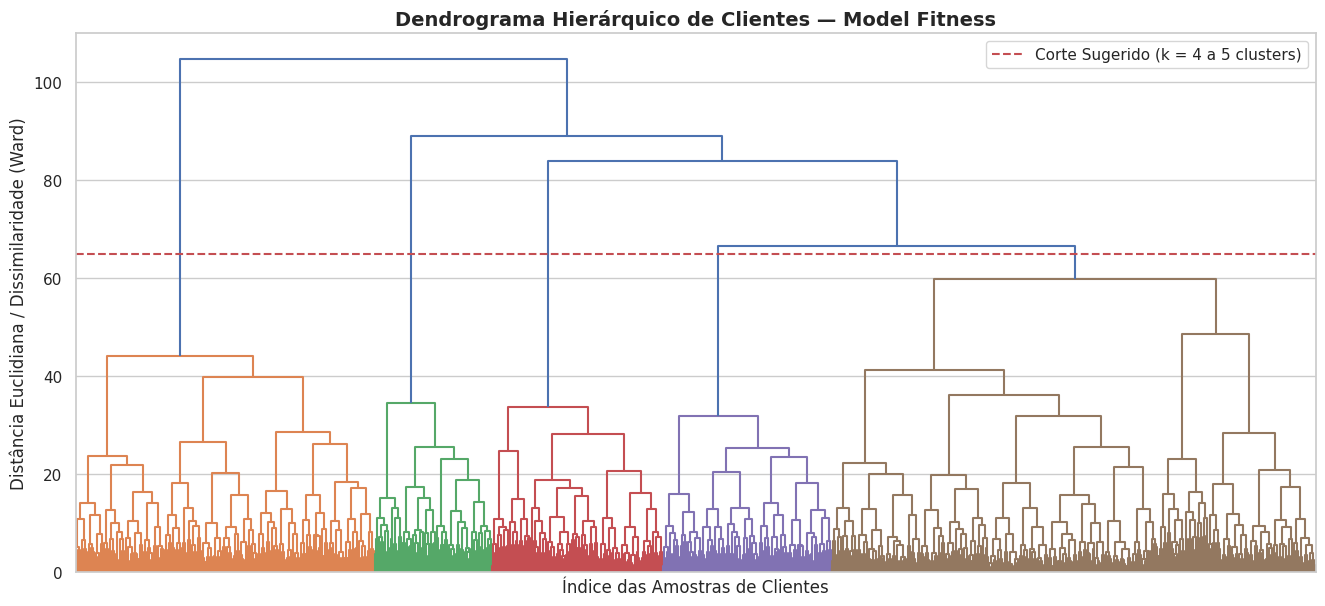

In [17]:
# 2. Construção da matriz de distâncias e plotagem do Dendrograma
linked = linkage(X_clustering_scaled, method='ward')

plt.figure(figsize=(16, 7))
dendrogram(linked, orientation='top', no_labels=True, color_threshold=65)
plt.title('Dendrograma Hierárquico de Clientes — Model Fitness', fontsize=14, fontweight='bold')
plt.xlabel('Índice das Amostras de Clientes')
plt.ylabel('Distância Euclidiana / Dissimilaridade (Ward)')
plt.axhline(y=65, color='r', linestyle='--', label='Corte Sugerido (k = 4 a 5 clusters)')
plt.legend()
plt.show()

In [18]:
# 3. Treinamento do K-Means com k = 5
kmeans = KMeans(n_clusters=5, random_state=0)
df['cluster'] = kmeans.fit_predict(X_clustering_scaled)

In [19]:
# 4. Médias das características por cluster
print('--- Médias das Características por Agrupamento (Cluster) ---')
cluster_summary = df.groupby('cluster').mean().T
display(cluster_summary.round(3))

--- Médias das Características por Agrupamento (Cluster) ---


cluster,0,1,2,3,4
gender,0.503,0.522,0.495,0.486,0.560
near_location,0.959,0.862,0.000,1.000,0.976
partner,0.783,0.470,0.463,0.350,0.357
promo_friends,0.574,0.306,0.079,0.240,0.230
phone,1.000,0.000,1.000,1.000,0.999
contract_period,10.889,4.787,2.352,1.948,2.669
group_visits,0.543,0.426,0.216,0.342,0.474
age,29.982,29.301,28.477,28.168,30.125
avg_additional_charges_total,160.761,143.958,135.458,131.622,161.658
month_to_end_contract,9.954,4.475,2.198,1.857,2.459


In [20]:

# 5. Volume de clientes e Taxa de Churn por Cluster
cluster_churn = df.groupby('cluster').agg(
    total_clientes=('churn', 'count'),
    taxa_churn=('churn', 'mean'),
    clientes_evadidos=('churn', 'sum'),
).reset_index()

cluster_churn['proporcao_base'] = (cluster_churn['total_clientes'] / len(df)) * 100
print('\n--- Volume e Taxa de Rotatividade por Cluster ---')
display(cluster_churn.round(3))


--- Volume e Taxa de Rotatividade por Cluster ---


,cluster,total_clientes,taxa_churn,clientes_evadidos,proporcao_base
0,0,1010,0.028,28,25.250
1,1,385,0.268,103,9.625
2,2,505,0.444,224,12.625
3,3,1262,0.514,649,31.550
4,4,838,0.068,57,20.950


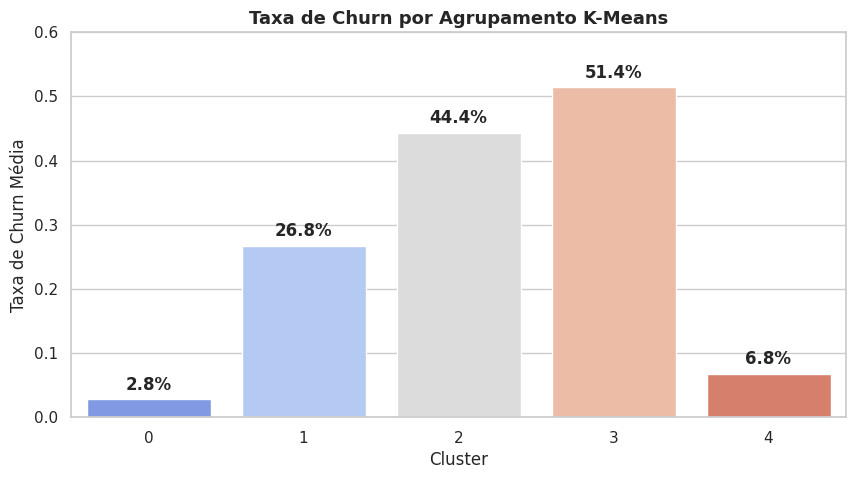

In [21]:
# 6. Visualização comparativa da taxa de churn entre agrupamentos
plt.figure(figsize=(10, 5))
sns.barplot(data=cluster_churn, x='cluster', y='taxa_churn', palette='coolwarm')
plt.title('Taxa de Churn por Agrupamento K-Means', fontsize=13, fontweight='bold')
plt.xlabel('Cluster')
plt.ylabel('Taxa de Churn Média')
plt.ylim(0, 0.6)
for i, row in cluster_churn.iterrows():
    plt.text(row['cluster'], row['taxa_churn'] + 0.015, f"{row['taxa_churn']*100:.1f}%", ha='center', fontweight='bold')
plt.show()

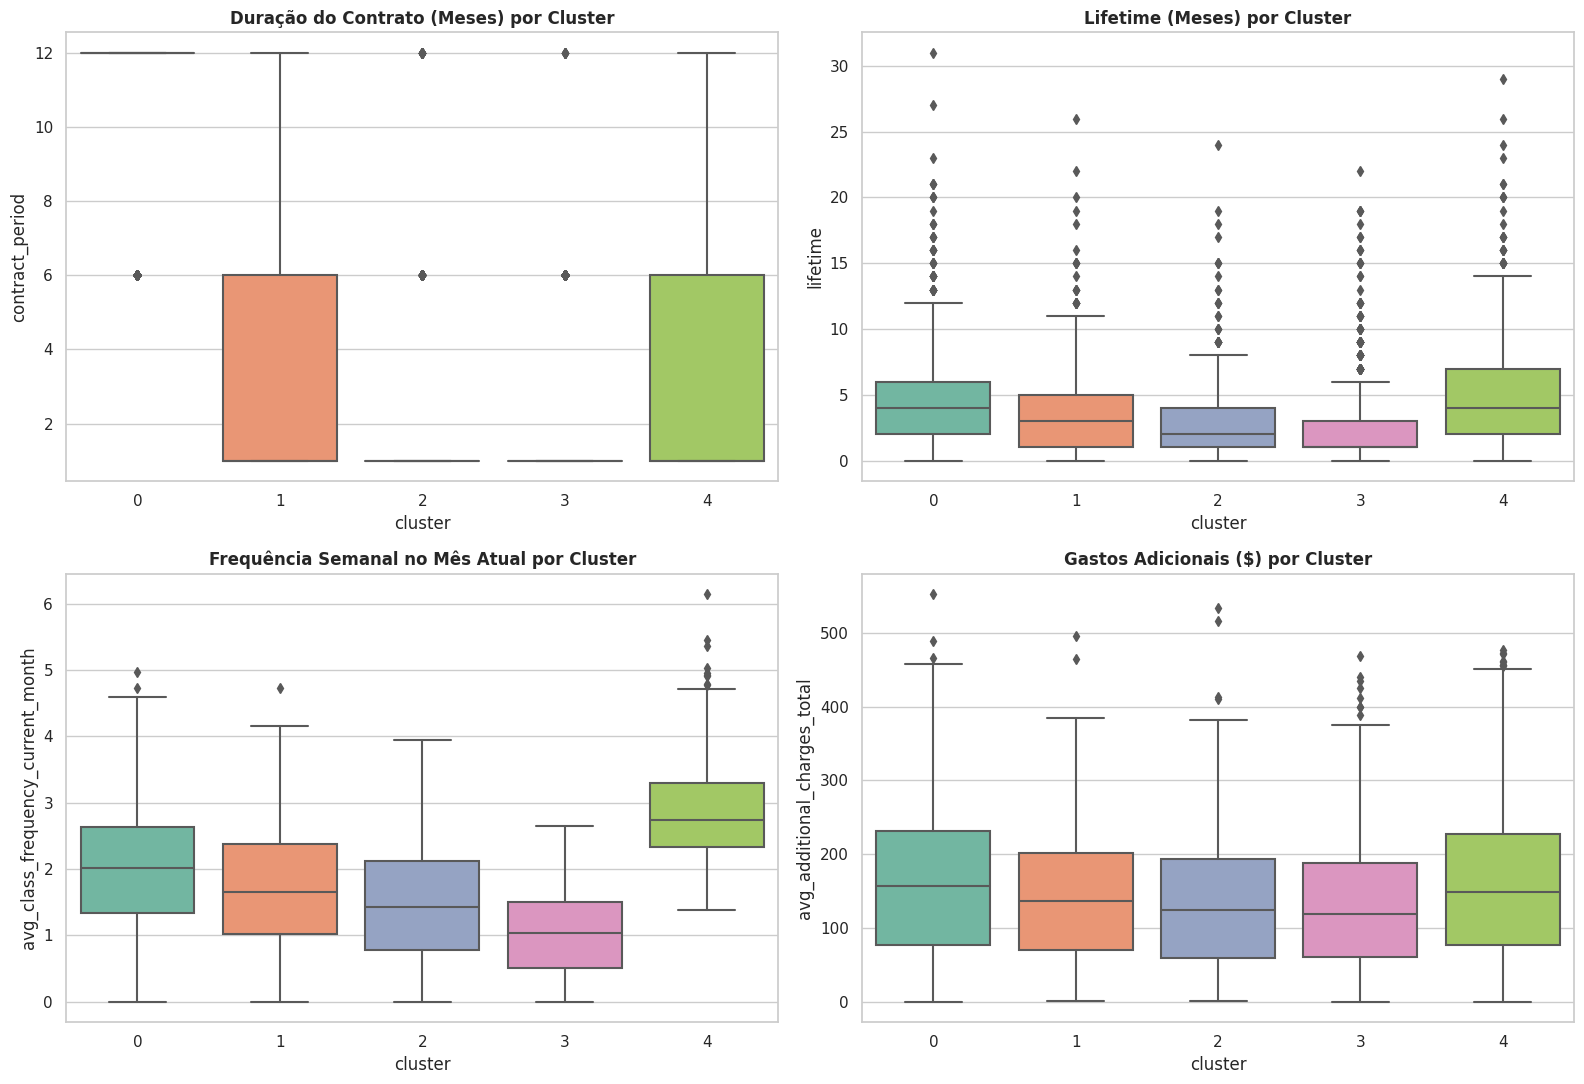

In [22]:
# 7. Visualização das distribuições de variáveis-chave por cluster
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.boxplot(x='cluster', y='contract_period', data=df, palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Duração do Contrato (Meses) por Cluster', fontweight='bold')

sns.boxplot(x='cluster', y='lifetime', data=df, palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('Lifetime (Meses) por Cluster', fontweight='bold')

sns.boxplot(x='cluster', y='avg_class_frequency_current_month', data=df, palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('Frequência Semanal no Mês Atual por Cluster', fontweight='bold')

sns.boxplot(x='cluster', y='avg_additional_charges_total', data=df, palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Gastos Adicionais ($) por Cluster', fontweight='bold')

plt.tight_layout()
plt.show()


# Passo 5. Conclusões e Recomendações de Negócio — Model Fitness

====================================================================
1. Diagnóstico Executivo e Visão Geral
====================================================================

A análise dos 4.000 registros de clientes da rede Model Fitness identificou uma taxa global de rotatividade (churn) de 26,5%. O comportamento de evasão na academia não acontece de forma abrupta, mas segue um padrão bem delineado de desengajamento progressivo ao longo do tempo.

Os fatores com maior correlação negativa com o cancelamento identificados na Análise Exploratória e nos Modelos Supervisionados foram:
- Tempo de vida como cliente (lifetime, r = -0,44): Clientes com menos de 2 meses de casa têm a maior vulnerabilidade. A média de permanência dos evadidos é de apenas 0,99 mês, contra 4,71 meses dos que continuam ativos.
- Queda abrupta de frequência semanal (avg_class_frequency_current_month, r = -0,41): Enquanto clientes fiéis treinam cerca de 2,03 vezes por semana no mês corrente, aqueles que estão prestes a sair caem sua média para 1,04 ida por semana (uma contração de ~48%).
- Idade (age, r = -0,40): O público mais jovem (média de 27 anos) evade com mais facilidade em comparação à faixa etária de 30 anos ou mais.
- Tipo de contrato (contract_period, r = -0,39): O contrato de apenas 1 mês responde pela esmagadora maioria dos desligamentos. Contratos semestrais e anuais criam barreiras psicológicas e financeiras fortes contra o abandono.
- Gastos em serviços adicionais (avg_additional_charges_total): Membros retidos consom em média $158,45 no ecossistema interno (café, produtos, massagens), enquanto os que cancelam gastam em média $115,08.

====================================================================
2. Desempenho dos Modelos Preditivos de Machine Learning
====================================================================

Na tarefa de prever a probabilidade de rotatividade no mês seguinte, avaliamos dois algoritmos supervisionados no conjunto de teste:

- Acurácia (Accuracy):
  * Regressão Logística: 93,50%
  * Random Forest Classifier: 92,25%
  * Modelo Vencedor: Regressão Logística

- Precisão (Precision):
  * Regressão Logística: 89,60%
  * Random Forest Classifier: 87,50%
  * Modelo Vencedor: Regressão Logística

- Sensibilidade (Recall):
  * Regressão Logística: 85,38%
  * Random Forest Classifier: 82,55%
  * Modelo Vencedor: Regressão Logística

- F1-Score:
  * Regressão Logística: 87,44%
  * Random Forest Classifier: 84,95%
  * Modelo Vencedor: Regressão Logística

- ROC-AUC:
  * Regressão Logística: 0,9780
  * Random Forest Classifier: 0,9703
  * Modelo Vencedor: Regressão Logística

Decisão Técnica: A Regressão Logística apresentou desempenho superior em todas as métricas avaliadas, destacando-se principalmente na Sensibilidade / Recall (85,38%). Em modelos de prevenção de churn, a Sensibilidade é a métrica mais crítica, pois o custo de não detectar um cliente que vai embora (falso negativo) é muito superior ao custo de oferecer uma intervenção de retenção para quem já pretendia ficar.

====================================================================
3. Retratos de Usuários Típicos (Buyer Personas via K-Means, k = 5)
====================================================================

A segmentação não supervisionada revelou cinco grupos distintos de clientes na base:

Cluster 3 — Risco Crítico / Entrada Pontual:
- Tamanho: 1.262 clientes (31,55% da base).
- Taxa de Churn: 51,4% (o maior volume absoluto e percentual de perdas).
- Características: Contratos curtos (média de 1,95 mês), menor frequência de treino no mês corrente (1,01 ida/semana), baixo tempo de casa (lifetime de 2,44 meses) e menor gasto adicional ($131,62).
- Diagnóstico: Alunos novatos em planos mensais que perdem a motivação nas primeiras semanas.

Cluster 2 — Barreira Geográfica / Não Residentes:
- Tamanho: 505 clientes (12,63% da base).
- Taxa de Churn: 44,4% (risco alto).
- Características: 100% dos clientes NÃO residem nem trabalham perto da academia (near_location = 0), apresentam a menor taxa de participação em aulas coletivas (21,6%) e contratos curtos (média de 2,35 meses).
- Diagnóstico: A fricção da distância física desestimula a assiduidade na rotina diária.

Cluster 1 — Canal sem Telefone / Risco Moderado:
- Tamanho: 385 clientes (9,63% da base).
- Taxa de Churn: 26,8% (alinhado com a média geral de 26,5%).
- Características: Grupo marcado por clientes que não forneceram telefone (phone = 0), mas mantêm taxas medianas de parceria (47,0%) e frequência regular (1,72 ida/semana).
- Diagnóstico: Clientes reservados e de difícil contato direto, demandando canais alternativos de comunicação (e-mail/app).

Cluster 4 — Atletas Assíduos e Frequentes:
- Tamanho: 838 clientes (20,95% da base).
- Taxa de Churn: 6,8% (alta retenção).
- Características: Maior frequência semanal de treinos (média de 2,85 vezes no mês), maior lifetime (4,90 meses) e alto gasto em serviços extras ($161,66).
- Diagnóstico: Praticantes consolidados, altamente disciplinados e engajados com o espaço.

Cluster 0 — Corporativos Hiperleais:
- Tamanho: 1.010 clientes (25,25% da base).
- Taxa de Churn: 2,8% (núcleo mais fiel e seguro da rede).
- Características: Contratos longos (média de 10,89 meses), fortíssima adesão a empresas parceiras (78,3%) e indicação de amigos (57,4%), alta presença em aulas em grupo (54,3%) e gastos extras elevados ($160,76).
- Diagnóstico: O perfil com maior Lifetime Value (LTV), blindado por contratos de longo prazo e laços sociais/corporativos.

====================================================================
4. Recomendações Estratégicas e Plano de Ação
====================================================================

1. Sistema de Alerta Antecipado (Early Warning Trigger):
- Regra do Gatilho: Intervir automaticamente quando a frequência semanal do aluno no mês corrente cair mais de 40% em relação à sua média histórica, ou atingir menos de 1,5 treino/semana.
- Ação: Disparar mensagens personalizadas via aplicativo ou WhatsApp convidando o aluno para um check-in de avaliação física gratuita, ajuste de ficha ou aula experimental coletiva.

2. Trilha de Onboarding para os Primeiros 60 Dias:
- Público-Alvo: Novos matriculados, com foco especial nos membros do Cluster 3.
- Ação: Criar programa de incentivo de início rápido: completando 8 treinos nos primeiros 30 dias, o aluno ganha créditos em consumação na lanchonete/shakes ou desconto em sessões de massagem, acelerando a formação do hábito de treino.

3. Redução da Fricção de Contratos Curtos:
- Público-Alvo: Clientes propensos a adquirir planos mensais avulsos.
- Ação: Oferecer planos de 6 e 12 meses via pagamento recorrente no cartão de crédito (sem comprometer o limite total) associados a uma garantia de 30 dias de cancelamento sem multa, diminuindo a barreira de entrada e estendendo a fidelização média.

4. Parcerias Corporativas e Facilidades de Acesso:
- Público-Alvo: Clientes dos Clusters 0, 1 e 2.
- Ação: Expandir o programa corporativo (Partner) para empresas vizinhas; implementar parcerias com estacionamentos locais para apoiar alunos distantes (Cluster 2) e desenvolver campanhas de comunicação via aplicativo da academia para atingir membros que não cadastraram telefone (Cluster 1).